In [1]:
# ruff: noqa: F405, F403, E402, F811
# no cache
%load_ext autoreload
%autoreload 2

In [3]:
from ptspy import *
from ptspy.more import *

In [ ]:
def perforate(size, hole=10):
    steps = populate(21, increment=30)  # [0, 30, 60 ... 270]
    edges = skia.Path()
    for s in steps:
        edges.addCircle(s, 0, hole)
        edges.addCircle(0, s, hole)
        edges.addCircle(size[0], s, hole)
        edges.addCircle(s, size[1], hole)
    return edges


padding = 25.0
bounds = P([padding, padding], [600 - padding, 600 - padding])
boundSize = 600 - padding * 2
boundRect = Rectangle.helper(bounds)


def stampId(form, num, adjust=0, color="fff"):
    offset = [480, 160]
    offset[0] -= 80 * (len(str(num)) - 1) - adjust + 10
    form.font(150, "Lexend").fillOnly(color).text(offset, str(num))


def save(img, filename="stamp.png"):
    # Save the image with transparency
    img.save(filename, skia.kPNG)
    print(f"Saved {filename} with transparency")

### 0

Fontconfig warning: "/usr/share/fontconfig/conf.avail/05-reset-dirs-sample.conf", line 6: unknown element "reset-dirs"


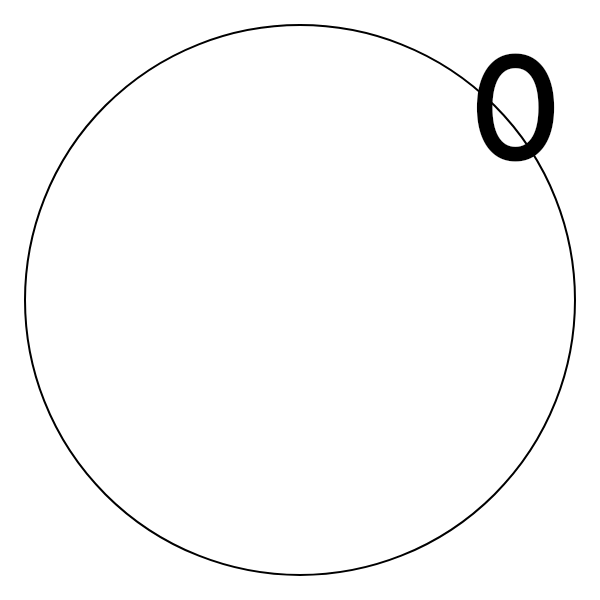

In [5]:
@frame(bg="fff", size=(600, 600))
def draw(form):
    form.fillOnly("fff").rect(bounds)
    form.strokeOnly("000", 2).circle(bounds)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 0, color="000")


draw()

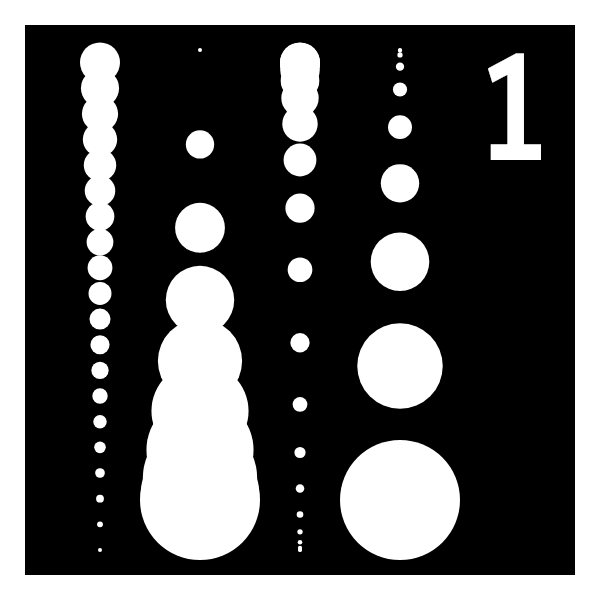

In [6]:
@frame(bg="fff", size=(600, 600))
def draw(form):
    one = steps([100, padding * 2.5, 20], [100, boundSize, 2], count=20, shaping="linear")
    two = steps([200, padding * 2, 2], [200, boundSize - padding * 2, 60], count=10, shaping="quadraticOut")
    three = steps([300, padding * 2.5, 20], [300, boundSize, 2], count=20, shaping="cubicInOut")
    # custom shaping function
    four = steps(
        [400, padding * 2, 2],
        [400, boundSize - padding * 2, 60],
        count=10,
        shaping=lambda t, a, b: a + (b - a) * (t * t * t),
    )

    form.fillOnly("000").rect(bounds)
    form.fillOnly("fff").points(one).points(two).points(three).points(four)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 1, color="fff", adjust=5)


draw()

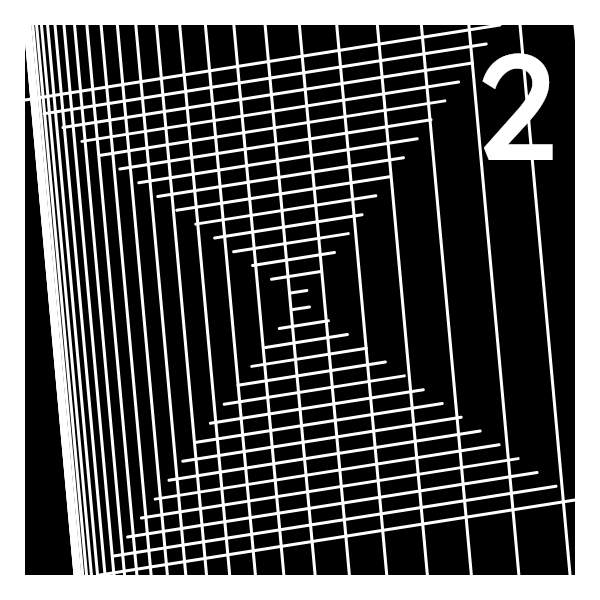

In [7]:
@frame(bg="fff", size=(600, 600))
def draw(form):
    top = steps(25, 575, 30, shaping="cubicIn")
    # reshape with new axis and append 0. shape is now (n,2)
    top = expand(top[:, np.newaxis], 0)
    lines = np.stack([top + [0, bounds[0][1]], top + [padding * 2, bounds[1][1]]], axis=1)

    # or just step through 2D directly
    another = np.stack([steps([25, 100], [575, 500], 30), steps([500, 25], [100, 575], 30)], axis=1)

    form.fillOnly("000").rect(bounds)
    form.strokeOnly("fff", 3).lines(np.concatenate([lines, another]))

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 2, color="fff", adjust=5)


draw()

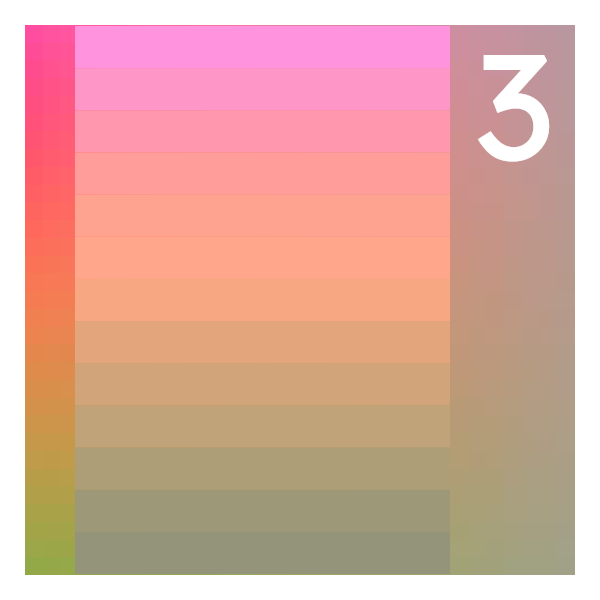

In [8]:
@frame(bg="ffffff", size=(600, 600))
def draw(form):
    # create a color cube of 100 steps
    cc = colorCube(steps=100)
    # Indices are (H, C, L) - hue, chroma, lightness
    start = P(0, 99, 90)
    end = P(30, 19, 60)
    # get a sub-cube
    indices = colorInterpolation(cc, start, end, steps=30, asPath=False)
    first = np.squeeze(indices, axis=0)
    form.image(first[:, :, 25].T, bounds)  # draw a slice

    # get a sub-path
    indices = colorInterpolation(cc, start, end, steps=12, asPath=True)
    form.colorMap(indices, [bounds[0] + [50, 1], bounds[1] - [125, 1]])

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 3, adjust=5)


draw()

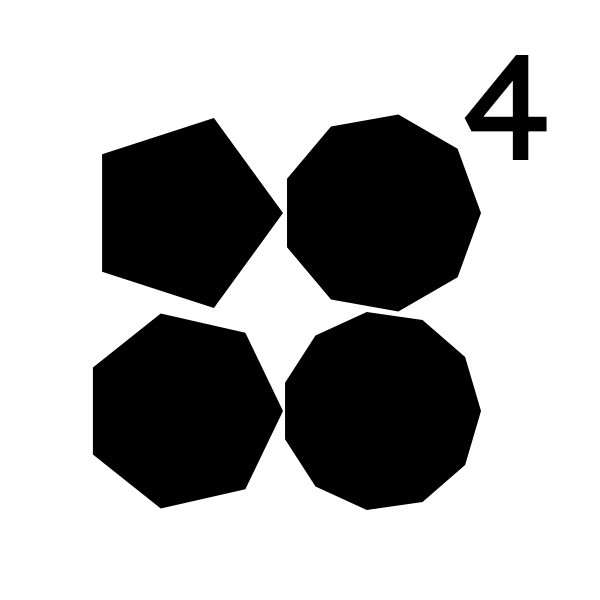

In [9]:
@frame(bg="ffffff", size=(600, 600))
def draw(form):
    # partial function
    poly = regularPolygon(center=TBD, radius=form.width / 6, sides=TBD, closed=True)

    centers = P([0.33, 0.33], [0.33, 0.66], [0.66, 0.33], [0.66, 0.66]) * form.size - [15, -15]
    shapes = [poly(center=c, sides=s) for c, s in zip(centers, [5, 7, 9, 11])]

    form.fillOnly("000", 3).polygons(shapes)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 4, color="000", adjust=-10)


draw()

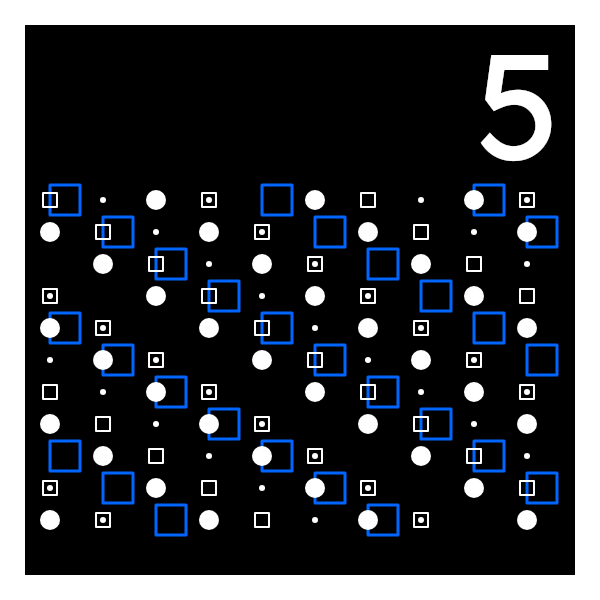

In [10]:
@frame(bg="fff", size=(600, 600))
def draw(form):
    points = gridPoints([10, 11], [53, 32]) + [50, 200]
    regions = pointsToRegions(points[::4], [30, 30], [0, 0.5])

    form.fillOnly("000").rect(bounds)

    form.strokeOnly("06f", 3).rects(regions)
    form.fillOnly("fff").points(points[1::2], 3).points(points[1::3], 10)
    form.strokeOnly("fff", 2).points(points[::3], 7, style="rect")

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 5, color="fff", adjust=5)


draw()

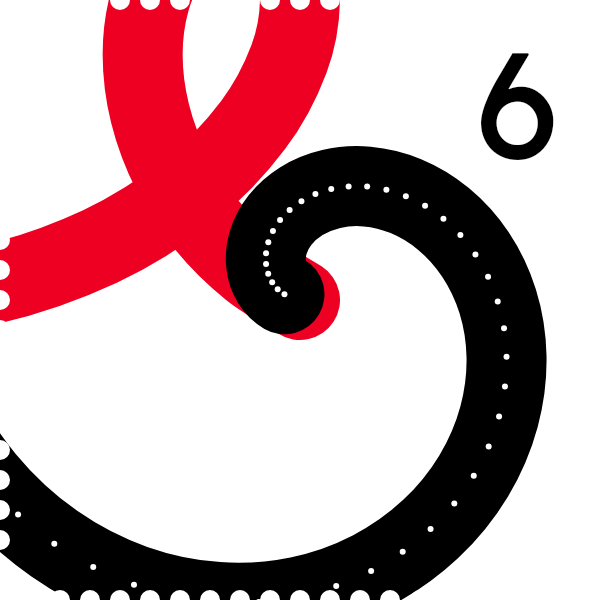

In [11]:
@frame(bg="fff", size=(600, 600))
def draw(form):
    original = regularPolygon(center=form.size / 2, radius=form.width / 3, sides=24, closed=True)
    poly = rotate2D(original, PI, origin=TBD)
    spiralA = P([scale2D(p, i * 1 / 12, form.size / 2) for i, p in enumerate(poly(origin=form.size / 2))])
    spiralB = P([scale2D(p, i * 1 / 8, form.size / 2) for i, p in enumerate(poly(origin=form.size / 3))])

    form.strokeOnly("E02", 80).cardinal(spiralB, tension=0.5)
    form.strokeOnly("000", 80).bspline(spiralA)
    form.fillOnly("FFF").points(sampleBspline(spiralA, numSamples=2), 3)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 6, color="000", adjust=5)


draw()

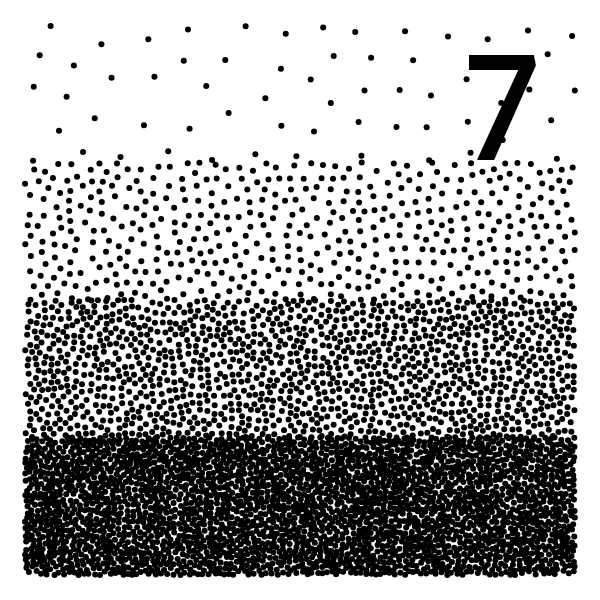

In [12]:
@frame(bg="ffffff", size=(600, 600))
def draw(form):
    bands = Rectangle.strips(bounds, 0.25, axis=1)
    form.fillOnly("000").points(poissonDisc(bands[0], 30), 3)
    form.points(poissonDisc(bands[1], 10), 3)
    form.points(poissonDisc(bands[2], 6), 3)
    form.points(poissonDisc(bands[3], 4), 3)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 7, color="000", adjust=-10)


draw()

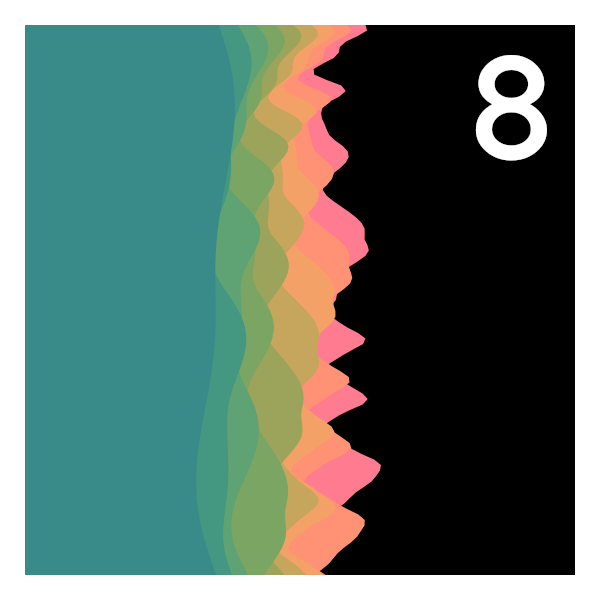

In [13]:
@frame(bg="fff", size=(600, 600))
def draw(form):

    # create a color cube of 50 steps
    cc = colorCube(steps=50)
    colors = colorInterpolation(cc, P(0, 49, 40), P(30, 15, 25), steps=10)

    perlin = createPerlinNoise2D([101, 1], seed=123)
    corners = P([boundSize, boundSize], [0, boundSize]) + padding

    form.fillOnly("000").rect(bounds)

    # show different frequencies
    for i in range(1, 10):
        values = perlin(freq=1 - i / 10, octaves=2).reshape(-1)
        wave = attachPositionIndex(values) * P(boundSize / 100, 200) + P(padding, 250 + i * 15)
        polygon = rotate2D(np.append(wave, corners, axis=0), PI / 2, boundRect.center)
        form.fillOnly(colors[i]).polygon(polygon)

    # make a stamp
    form.erase(perforate(form.size))
    stampId(form, 8, color="fff", adjust=-2)


draw()